# 03 - BTC Correlation

How much does BTC drive ETH? Lead/lag analysis.


## Setup

In [1]:
# --- setup --------------------------------------------------------
import sys, json
sys.path.insert(0, r"D:\\Projects\\done\\eth_bot\\eth_bot_v2")
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 60)
plt.rcParams["figure.figsize"] = (13, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
np.random.seed(42)

SYMBOL = "ETHUSDT"
OUT = Path(r"D:\\Projects\\done\\eth_bot\\eth_bot_v2") / "reports" / "forecasts"
OUT.mkdir(parents=True, exist_ok=True)
DB = Path(r"D:\\Projects\\done\\eth_bot\\eth_bot_v2") / "database" / "market.db"

def sql(q, **p):
    with sqlite3.connect(DB) as c:
        return pd.read_sql_query(q, c, params=p)

from database.config.api.binance import get_klines

def fetch(symbol, interval, limit=500):
    raw = get_klines(symbol, interval=interval, limit=limit)
    df = pd.DataFrame(raw, columns=["open_time","open","high","low","close",
        "volume","close_time","quote_volume","trades","taker_base","taker_quote","ignore"])
    df["date"] = pd.to_datetime(df["open_time"], unit="ms", utc=True).dt.tz_convert(None)
    for c in ("open","high","low","close","volume"):
        df[c] = df[c].astype(float)
    return df[["date","open","high","low","close","volume"]].set_index("date").iloc[:-1]

def action_block(name, action, reason, price=None, entry=None, stop=None,
                 target=None, conf=None, extra=None):
    print("=" * 62)
    print(f"  {name}")
    print("=" * 62)
    print(f"  time   : {datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M')} UTC")
    if price is not None: print(f"  price  : {price:,.2f}")
    if conf  is not None: print(f"  conf   : {conf:.2f}")
    print(f"  ACTION : {action}")
    print(f"  REASON : {reason}")
    if entry is not None:
        print(f"  entry  : {entry:,.2f}   stop: {stop:,.2f}   target: {target:,.2f}")
    if extra:
        for k, v in extra.items():
            print(f"  {k:<6} : {v}")
    print("=" * 62)
    return {"action": action, "reason": reason, "price": price,
            "entry": entry, "stop": stop, "target": target, "conf": conf}

## 1. Fetch both

In [2]:
eth = fetch("ETHUSDT", "1d", 500)
btc = fetch("BTCUSDT", "1d", 500)
both = pd.concat([eth.close.rename("ETH"), btc.close.rename("BTC")], axis=1).dropna()
print("rows:", len(both))

rows: 499


## 2. Returns correlation

In [3]:
r = both.pct_change().dropna()
print("corr (contemporary):", round(r.corr().iloc[0,1], 4))

corr (contemporary): 0.8578


## 3. Lead/lag — does BTC lead ETH?

In [4]:
lags = range(-5, 6)
cors = [r["BTC"].shift(l).corr(r["ETH"]) for l in lags]
best = list(lags)[int(np.argmax(cors))]
print("best lag (BTC leads ETH if negative):", best)
for l, c in zip(lags, cors):
    print(f"  lag {l:+d}: {c:+.4f}")

best lag (BTC leads ETH if negative): 0
  lag -5: -0.0227
  lag -4: +0.0481
  lag -3: -0.0527
  lag -2: -0.0218
  lag -1: +0.0145
  lag +0: +0.8578
  lag +1: +0.0271
  lag +2: -0.0234
  lag +3: -0.0235
  lag +4: +0.0096
  lag +5: +0.0135


## 4. Chart — rolling 30d correlation

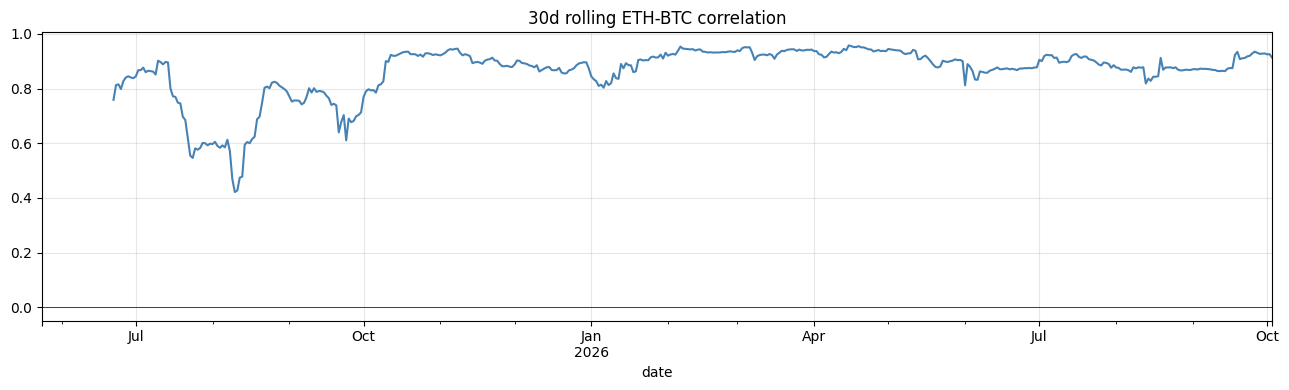

In [5]:
roll_corr = r["ETH"].rolling(30).corr(r["BTC"])
fig, ax = plt.subplots()
roll_corr.plot(ax=ax, color="steelblue", title="30d rolling ETH-BTC correlation")
ax.axhline(0, color="black", lw=0.5)
plt.tight_layout(); plt.show()

## 5. BTC-derived ETH signal

In [6]:
btc_ret_today = r["BTC"].iloc[-1]
eth_ret_today = r["ETH"].iloc[-1]
btc_momentum = r["BTC"].tail(5).mean()

if btc_momentum > 0.01:
    action, reason = "LONG", "BTC 5d momentum positive — alt tailwind"
elif btc_momentum < -0.01:
    action, reason = "SHORT", "BTC 5d momentum negative — alt headwind"
else:
    action, reason = "FLAT", "BTC flat — no signal"

action_block("ETH via BTC", action, reason,
    price=float(both["ETH"].iloc[-1]),
    extra={"btc_5d_mom": f"{btc_momentum*100:+.2f}%",
           "corr_30d": f"{roll_corr.iloc[-1]:.3f}"})

  ETH via BTC
  time   : 2026-10-04 10:40 UTC
  price  : 2,687.23
  ACTION : FLAT
  REASON : BTC flat — no signal
  btc_5d_mom : +0.30%
  corr_30d : 0.913


{'action': 'FLAT',
 'reason': 'BTC flat — no signal',
 'price': 2687.23,
 'entry': None,
 'stop': None,
 'target': None,
 'conf': None}